# 2HS 数值分析

比较可积半离散格式（Integrable）与固定网格中心差分（FD）的单孤子、二孤子计算。


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 计算使用 IEEE 754 双精度。
np.set_printoptions(precision=12)
pd.set_option("display.precision", 12)

# 图中文字与公式统一使用随 Matplotlib 提供的 STIX 字体。
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["STIXGeneral", "Times New Roman", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "mathtext.default": "it",
    "text.usetex": False,
})


## 1　单孤子与初始网格

考虑 $c=1$ 的 2HS 系统

$$u_{tx}-uu_{xx}-\frac12u_x^2-4u-\frac12(\rho^2-1)=0,\qquad \rho_t=(u\rho)_x.\tag{1}$$

取原文图 1、图 3 的参数 $p=5$、$q=1.25$、$\xi_0=\eta_0=0$，相应的连续单孤子解为

$$\theta=\frac{15}{4}X-\frac35t,\qquad
x=X-\frac12+\frac3{10}\tanh\frac\theta2,\qquad
u=\frac9{100}\operatorname{sech}^2\frac\theta2,\qquad
\rho=\frac{16}{25-9\tanh^2(\theta/2)}.\tag{2}$$

取 $N=2400$、$a=0.005$；具体空间格式见第 2 节。


默认参数如下；计算域、网格数、时间和绘图范围均可在 `CONFIG` 中调整。

In [2]:
# 计算域使用辅助坐标 X；绘图和误差评价使用物理坐标 x。
CONFIG = dict(
    X_domain=(-6.0, 6.0),       # 辅助计算区间；物理端点由孤子映射给出
    N=2400,                    # 网格份数；a = 区间长度 / N
    dt=0.003125, T=0.5,         # 时间步长、终止时间
    xMin=-1.0, xMax=1.0,        # 误差表的评价区间
    evaluationPoints=32001,    # 评价与绘图采样点数
)
hs_cfg = CONFIG
hs_N = CONFIG["N"]
hs_Xleft, hs_Xright = CONFIG["X_domain"]
hs_dt, hs_T = CONFIG["dt"], CONFIG["T"]
hs_xmin, hs_xmax = CONFIG["xMin"], CONFIG["xMax"]
hs_neval = CONFIG["evaluationPoints"]
if not np.isfinite([hs_Xleft, hs_Xright, hs_dt, hs_T, hs_xmin, hs_xmax]).all():
    raise ValueError("计算域、时间、评价和绘图范围须取有限实数。")
if not (hs_Xleft < hs_Xright and hs_dt > 0 and hs_T >= 0 and hs_xmin < hs_xmax):
    raise ValueError("计算域、评价区间须递增，且 dt>0、T≥0。")
if not isinstance(hs_N, int) or not 20 <= hs_N <= 6400:
    raise ValueError("N 应为 20—6400 的整数。")
hs_a = (hs_Xright-hs_Xleft)/hs_N
if not isinstance(hs_neval, int) or not 101 <= hs_neval <= 64001:
    raise ValueError("评价点数应为 101—64001 的整数。")
hs_steps = round(hs_T/hs_dt)
if abs(hs_steps*hs_dt-hs_T) > 1e-12 or hs_steps > 3200:
    raise ValueError("T 须为 dt 的整数倍，且步数≤3200。")
print(pd.DataFrame([{
    "N": hs_N, "a": hs_a, "X 左端": hs_Xleft, "X 右端": hs_Xright,
    "dt": hs_dt, "T": hs_T, "时间步数": hs_steps, "评价点数": hs_neval,
}]).to_string(index=False))


   N     a  X 左端  X 右端       dt   T  时间步数  评价点数
2400 0.005  -6.0   6.0 0.003125 0.5   160 32001


以下代码给出式（2）的解析场、初始物理节点及 FD 端点。


In [3]:
def hs_exact_X(X, t):
    """式（2）的解析场；X 可以是标量或数组。"""
    X = np.asarray(X, dtype=float)
    z = np.tanh((3.75 * X - 0.6 * t) / 2)
    S = 1 - z * z
    zX = 1.875 * S
    zXX = -2 * zX * 1.875 * z
    J, JX = 1 + 0.3 * zX, 0.3 * zXX
    u, uX = 0.09 * S, -0.18 * z * zX
    uXX = -0.18 * (zX * zX + z * zXX)
    # 链式法则：d/dx=(1/J)d/dX，其中 J=dx/dX。
    uxx = (uXX * J - uX * JX) / (J * J * J)
    return dict(x=X - 0.5 + 0.3 * z, u=u, rho=1 / J, m=uxx + 2, X=X)

def hs_exact_physical(x, t):
    """利用 dx/dX>0，在 [x+0.2,x+0.8] 中二分反解 X。"""
    x = np.asarray(x, dtype=float)
    lo, hi = x + 0.2, x + 0.8
    for _ in range(60):
        mid = (lo + hi) / 2
        lower = hs_exact_X(mid, t)["x"] < x
        lo, hi = np.where(lower, mid, lo), np.where(lower, hi, mid)
    value = hs_exact_X((lo + hi) / 2, t)
    if np.max(np.abs(value["x"] - x)) > 2e-12:
        raise ArithmeticError("物理坐标反解未达到容差。")
    return value

hs_initial = hs_exact_X(hs_Xleft + np.arange(hs_N + 1) * hs_a, 0)
hs_left, hs_right = hs_initial["x"][[0, -1]]
hs_dx = (hs_right - hs_left) / hs_N
# 固定网格与初始动网格共用物理端点。
hs_fixed_x = hs_left + np.arange(hs_N + 1) * hs_dx
if hs_xmin <= hs_left or hs_xmax >= hs_right:
    raise ValueError("评价区间必须位于初始物理端点内部。")
print(pd.DataFrame([{
    "初始物理左端": hs_left, "初始物理右端": hs_right,
    "FD 的 dx": hs_dx, "峰值 u": 0.09, "谷值 rho": 0.64,
}]).to_string(index=False, formatters={
    "初始物理左端": "{:.1f}".format, "初始物理右端": "{:.1f}".format,
    "FD 的 dx": "{:.6f}".format,
}))


初始物理左端 初始物理右端  FD 的 dx  峰值 u  谷值 rho
  -6.8    5.8 0.005250  0.09    0.64


## 2　空间离散

### 2.1　Integrable

原连续方程为

$$u_{tx}-uu_{xx}-\frac12u_x^2-4u-\frac12(\rho^2-1)=0,
\qquad \rho_t=(u\rho)_x.$$

将辅助坐标 $X\in[-6,6]$ 等分为 $N=2400$ 段，
$X_k=-6+ka$、$a=0.005$；式（2）将 $X=-6,6$ 映为初始物理端点，
区间约为 $[-6.8,\,5.8]$。

令 $d_k=x_{k+1}-x_k$、$b_k=u_{k+1}-u_k$。$c=1$ 时的半离散方程为

$$\begin{aligned}
\dot d_k&=-b_k,\qquad \dot x_0=-u_0(t),\\
\dot b_k&=2d_k(u_{k+1}+u_k)
+\frac{[d_k^2-a(a-1)]^2-b_k^2}{2d_k}-\frac{d_k}{2}.
\end{aligned}\tag{3}$$

取解析左端值 $u_0(t)$，节点及密度按下式递推：

$$u_{k+1}=u_k+b_k,\qquad x_{k+1}=x_k+d_k,\qquad
\rho_{k+1/2}=\frac a{d_k}.\tag{4}$$

参数：$c=1$、$a=0.005$、$N=2400$、$\Delta t=0.003125$、$T=0.5$。
以下代码实现式（4）的恢复与式（3）的右端；RK4 时间递推见第 3 节。


In [4]:
def hs_integrable_fields(t, state):
    # 状态：[b_0,...,b_(N-1), d_0,...,d_(N-1), x_0]。
    b, d = state[:hs_N], state[hs_N:2 * hs_N]
    if not np.isfinite(state).all() or np.any(d <= 0):
        raise ArithmeticError("Integrable 出现非有限状态或非正胞元格距。")
    u0 = hs_exact_X(hs_Xleft, t)["u"]
    u = np.r_[u0, u0 + np.cumsum(b)]
    x = np.r_[state[-1], state[-1] + np.cumsum(d)]
    return dict(x=x, u=u, rhoX=(x[:-1] + x[1:]) / 2, rho=hs_a / d)

def hs_integrable_rhs(t, state):
    # 式（3）：b、d 和 x_0 的时间导数。
    u = hs_integrable_fields(t, state)["u"]
    b, d = state[:hs_N], state[hs_N:2 * hs_N]
    C = d * d - hs_a * (hs_a - 1)
    db = 2 * d * (u[1:] + u[:-1]) + (C * C - b * b) / (2 * d) - d / 2
    return np.r_[db, -b, -u[0]]


### 2.2　FD

对式（1）作 $x$ 微分，令 $m=u_{xx}+2$，原方程写成

$$m_t=um_x+2mu_x+\rho\rho_x,\qquad
\rho_t=u\rho_x+\rho u_x,\qquad u_{xx}=m-2.$$

在初始物理端点之间等分 2400 段，$x_i=x_L+i\Delta x$；
物理端点由解析坐标映射在 $X=-6,6$ 处给出，
单孤子、二孤子的区间分别约为 $[-6.8,\,5.8]$、$[-7.7,\,5.7]$。

中心差分及离散方程为

$$(D_1f)_i=\frac{f_{i+1}-f_{i-1}}{2\Delta x},\qquad
(D_2f)_i=\frac{f_{i+1}-2f_i+f_{i-1}}{\Delta x^2}.\tag{5}$$

$$\begin{aligned}
\dot m_i&=u_i(D_1m)_i+2m_i(D_1u)_i+\rho_i(D_1\rho)_i,\\
\dot\rho_i&=u_i(D_1\rho)_i+\rho_i(D_1u)_i,\\
u_{i+1}-2u_i+u_{i-1}&=\Delta x^2(m_i-2).
\end{aligned}\tag{6}$$

参数：$c=1$、$N=2400$、$\Delta t=0.003125$、$T=0.5$；
$\Delta x\approx0.005250$（单孤子）或 $\Delta x\approx0.005591$（二孤子）。
两端取解析值。以下代码先联立求出 $u$，再计算式（6）的时间导数。


In [5]:
def hs_recover_u(m, ub_left, ub_right):
    # Thomas 消元：u_(i-1)-2u_i+u_(i+1)=dx^2*(m_i-2)。
    count = hs_N - 1
    c, d = np.zeros(count), np.zeros(count)
    for j in range(count):
        diagonal = -2 - (c[j - 1] if j else 0)
        rhs = hs_dx * hs_dx * (m[j + 1] - 2)
        if j == 0:
            rhs -= ub_left
        if j == count - 1:
            rhs -= ub_right
        c[j] = 1 / diagonal if j < count - 1 else 0
        d[j] = (rhs - (d[j - 1] if j else 0)) / diagonal
    u = np.empty(hs_N + 1)
    u[0], u[-1] = ub_left, ub_right
    for j in range(count - 1, -1, -1):
        u[j + 1] = d[j] - (c[j] * u[j + 2] if j < count - 1 else 0)
    return u

def hs_fd_fields(t, state):
    # FD 状态为内部 m 与 rho，端点取解析边界。
    boundary = hs_exact_physical(np.array([hs_left, hs_right]), t)
    m = np.r_[boundary["m"][0], state[:hs_N - 1], boundary["m"][1]]
    rho = np.r_[boundary["rho"][0], state[hs_N - 1:], boundary["rho"][1]]
    if not np.isfinite(m).all() or not np.isfinite(rho).all() or np.any(rho <= 0):
        raise ArithmeticError("FD 出现非有限状态或非正密度。")
    u = hs_recover_u(m, *boundary["u"])
    return dict(x=hs_fixed_x, u=u, rhoX=hs_fixed_x, rho=rho, m=m)

def hs_fd_rhs(t, state):
    # 式（6）：固定网格上的一阶中心差分。
    fields = hs_fd_fields(t, state)
    m, rho, u = (fields[k] for k in ("m", "rho", "u"))
    ux = (u[2:] - u[:-2]) / (2 * hs_dx)
    mx = (m[2:] - m[:-2]) / (2 * hs_dx)
    rx = (rho[2:] - rho[:-2]) / (2 * hs_dx)
    return np.r_[u[1:-1] * mx + 2 * m[1:-1] * ux + rho[1:-1] * rx,
                 u[1:-1] * rx + rho[1:-1] * ux]


### 2.3　网格策略与初值

Integrable 的物理网格随 $\dot x=-u$ 运动，FD 保持初始物理节点固定。
两个算例均取 $N=2400$、$a=0.005$，初值为

$$b_k^0=u_{k+1}^0-u_k^0,\qquad d_k^0=x_{k+1}^0-x_k^0,
\qquad m_i^0=(D_2u^0)_i+2,\qquad \rho_i^0=\rho(x_i,0).$$


In [6]:
def hs_initial_states():
    # 初始 m 使用与演化一致的二阶差分模板。
    fields = hs_exact_physical(hs_fixed_x, 0)
    u0 = fields["u"]
    integrable = np.r_[np.diff(hs_initial["u"]), np.diff(hs_initial["x"]), hs_left]
    m0 = (u0[2:] - 2 * u0[1:-1] + u0[:-2]) / (hs_dx * hs_dx) + 2
    fd = np.r_[m0, fields["rho"][1:-1]]
    return integrable, fd


## 3　时间推进

记空间系统为 $\dot z=\mathcal F(t,z)$，时间递推采用 RK4：

$$\begin{aligned}
K_1&=\mathcal F(t_n,z^n),&
K_2&=\mathcal F\!\left(t_n+\frac{\Delta t}{2},z^n+\frac{\Delta t}{2}K_1\right),\\
K_3&=\mathcal F\!\left(t_n+\frac{\Delta t}{2},z^n+\frac{\Delta t}{2}K_2\right),&
K_4&=\mathcal F(t_n+\Delta t,z^n+\Delta tK_3),\\
z^{n+1}&=z^n+\frac{\Delta t}{6}(K_1+2K_2+2K_3+K_4).
\end{aligned}\tag{7}$$

取 $\Delta t=0.003125$、$T=0.5$，共 160 步。每个阶段按式（4）或（6）恢复场值。


In [7]:
def hs_rk4_step(rhs, t, state, delta):
    # 式（7）：每一级重新恢复场值和解析边界。
    k1 = rhs(t, state)
    k2 = rhs(t + delta / 2, state + delta / 2 * k1)
    k3 = rhs(t + delta / 2, state + delta / 2 * k2)
    k4 = rhs(t + delta, state + delta * k3)
    return state + delta * (k1 + 2 * k2 + 2 * k3 + k4) / 6


按式（7）从解析初值推进到 $T=0.5$。


In [8]:
# 保存原有推进过程中的快照，末尾画图不再重新求解。
from types import FunctionType
hs_histories = {}
hs_saved_steps = set(np.unique(np.linspace(0, hs_steps, min(33, hs_steps+1), dtype=int)))
def hs_start_history(case):
    reference = FunctionType(hs_exact_physical.__code__, dict(globals()),
                             hs_exact_physical.__name__, hs_exact_physical.__defaults__)
    hs_histories[case] = dict(reference=reference, records=[], T=hs_T)
def hs_capture(case, step_index):
    if step_index not in hs_saved_steps:
        return
    t = step_index*hs_dt
    fields = {'Integrable': hs_integrable_fields(t, hs_integrable),
              'FD': hs_fd_fields(t, hs_fd)}
    hs_histories[case]['records'].append((t, {
        name: {key: np.array(value, copy=True) for key, value in field.items()}
        for name, field in fields.items()}))

In [9]:
hs_integrable, hs_fd = hs_initial_states()
hs_start_history("one")
hs_capture("one", 0)
# 时间层 t_n=n*dt；再次执行本单元会从当前配置的初值开始。
for hs_step in range(hs_steps):
    hs_t = hs_step * hs_dt
    hs_integrable = hs_rk4_step(hs_integrable_rhs, hs_t, hs_integrable, hs_dt)
    hs_fd = hs_rk4_step(hs_fd_rhs, hs_t, hs_fd, hs_dt)
    hs_capture("one", hs_step+1)
hs_live_fields = {
    "Integrable": hs_integrable_fields(hs_T, hs_integrable),
    "FD": hs_fd_fields(hs_T, hs_fd),
}
print(pd.DataFrame([
    {"方案": name, "已推进步数": hs_steps, "当前时间": hs_T, "物理节点数": len(f["x"])}
    for name, f in hs_live_fields.items()
]).to_string(index=False))


        方案  已推进步数  当前时间  物理节点数
Integrable    160   0.5   2401
        FD    160   0.5   2401


## 4　单孤子误差与波形

在 $x\in[-1,1]$ 的 32001 个等距点 $\mathcal G$ 上，线性插值后计算

$$E_u(t)=\max_{x\in\mathcal G}|u_h(x,t)-u(x,t)|,\qquad
E_\rho(t)=\max_{x\in\mathcal G}|\rho_h(x,t)-\rho(x,t)|.\tag{8}$$

以下代码实现插值与误差计算。误差图按 `plot_xlim` 指定的区间等分为 100 段，取段内最大绝对误差。


In [10]:
def hs_interpolate(xs, values, targets):
    # 物理节点上的分段线性重构。
    if targets[0] < xs[0] or targets[-1] > xs[-1]:
        raise ValueError("数值网格未覆盖整个评价区间。")
    # side='left' 与原报告在恰好落于节点时采用相同的左区间。
    j = np.clip(np.searchsorted(xs, targets, side="left") - 1, 0, len(xs) - 2)
    weight = (targets - xs[j]) / (xs[j + 1] - xs[j])
    return values[j] + weight * (values[j + 1] - values[j])


In [11]:
# 式（8）：公共物理网格上的最大绝对误差。
hs_xx = hs_xmin + (hs_xmax - hs_xmin) * np.arange(hs_neval) / (hs_neval - 1)
hs_reference = hs_exact_physical(hs_xx, hs_T)
hs_results, hs_result_rows = {}, []
for hs_name, hs_fields in hs_live_fields.items():
    hs_u = hs_interpolate(hs_fields["x"], hs_fields["u"], hs_xx)
    hs_rho = hs_interpolate(hs_fields["rhoX"], hs_fields["rho"], hs_xx)
    hs_eu = np.abs(hs_u - hs_reference["u"])
    hs_er = np.abs(hs_rho - hs_reference["rho"])
    hs_r = dict(Eu=hs_eu.max(), Erho=hs_er.max(), eu=hs_eu, er=hs_er,
                u=hs_u, rho=hs_rho, minDx=np.diff(hs_fields["x"]).min(),
                minRho=hs_fields["rho"].min())
    hs_results[hs_name] = hs_r
    hs_result_rows.append({"方案": hs_name, "E_u(T)": hs_r["Eu"],
                           "E_rho(T)": hs_r["Erho"], "终点最小格距": hs_r["minDx"],
                           "终点最小密度": hs_r["minRho"]})
print(pd.DataFrame(hs_result_rows).to_string(index=False))

hs_single_summary = {name: dict(Eu=float(r['Eu']), Erho=float(r['Erho']))
                     for name, r in hs_results.items()}


        方案         E_u(T)       E_rho(T)         终点最小格距         终点最小密度
Integrable 0.010012788547 0.001149677289 0.004971398357 0.640451344712
        FD 0.000000914396 0.000002907427 0.005250000000 0.640000645407


## 5　二孤子

取 $p_1=1.1$、$p_2=1.25$、$q_1=11$、$q_2=5$、$c=1$，相位常数均为 $\log6.5$。
连续二孤子的 $\tau$ 函数为

$$\begin{aligned}
f&=1+e^{\theta_1}+e^{\theta_2}+A_{12}e^{\theta_1+\theta_2},
\qquad A_{12}=\frac{12}{507},\\
\theta_i&=(p_i-q_i)X+\left(\frac1{p_i}-\frac1{q_i}\right)t+\log6.5.
\end{aligned}\tag{9}$$

相应的物理坐标与场为

$$u=\partial_t^2\log f,\qquad
x=X-\partial_t\log f-\frac1{q_1}-\frac1{q_2},\qquad
\rho=\frac1{1-\partial_X\partial_t\log f}.\tag{10}$$

归一化后的四项指数构成权重。$u$ 是时间指数系数的方差，
$J=\partial x/\partial X$ 由时间、空间指数系数的协方差给出；
进一步的混合导数确定 $m=u_{xx}+2$，供 FD 边界使用。


In [12]:
# 四项 τ 函数的指数系数；q_i=p_i/(p_i-1) 对应 c=1。
hs_two_p = np.array([1.1, 1.25])
hs_two_q = np.array([11.0, 5.0])
hs_two_phase = np.log(6.5)
hs_two_A = 12 / 507
if not np.allclose(hs_two_q, hs_two_p / (hs_two_p - 1)):
    raise ValueError("p、q 必须满足 c=1 的孤子参数约束。")
hs_two_beta = np.r_[0, hs_two_p-hs_two_q, np.sum(hs_two_p-hs_two_q)][:, None]
hs_two_omega = np.r_[0, 1/hs_two_p-1/hs_two_q,
                     np.sum(1/hs_two_p-1/hs_two_q)][:, None]
hs_two_logcoef = np.array([0, hs_two_phase, hs_two_phase,
                          2*hs_two_phase + np.log(hs_two_A)])[:, None]
hs_two_shift = float(np.sum(1/hs_two_q))

def hs_two_exact_X(X, t):
    """u、J=dx/dX 和 m=u_xx+2 均由 τ 的解析导数计算。"""
    X = np.asarray(X, dtype=float)
    flat = X.reshape(-1)
    logs = hs_two_beta*flat + hs_two_omega*t + hs_two_logcoef
    # 减去列最大值避免指数溢出，不改变归一化权重。
    weights = np.exp(logs - np.max(logs, axis=0))
    weights /= np.sum(weights, axis=0)
    mean_o = np.sum(weights*hs_two_omega, axis=0)
    mean_b = np.sum(weights*hs_two_beta, axis=0)
    do, db = hs_two_omega-mean_o, hs_two_beta-mean_b
    u = np.sum(weights*do**2, axis=0)
    cov = np.sum(weights*do*db, axis=0)
    J = 1-cov
    JX = -np.sum(weights*do*db**2, axis=0)
    uX = np.sum(weights*do**2*db, axis=0)
    uXX = (np.sum(weights*do**2*db**2, axis=0)
           - u*np.sum(weights*db**2, axis=0) - 2*cov**2)
    if not np.isfinite(J).all() or np.any(J <= 0):
        raise ArithmeticError("二孤子物理坐标要求 J=dx/dX>0。")
    uxx = (uXX*J-uX*JX)/J**3
    return {k: value.reshape(X.shape) for k, value in dict(
        x=flat-mean_o-hs_two_shift, u=u, rho=1/J, m=uxx+2,
        X=flat, J=J, uX=uX, uXX=uXX, JX=JX).items()}

def hs_two_exact_physical(x, t):
    """由 τ 权重的凸组合界定 X 的区间，再二分反解。"""
    x = np.asarray(x, dtype=float)
    lo = x + hs_two_shift + float(np.min(hs_two_omega))
    hi = x + hs_two_shift + float(np.max(hs_two_omega))
    for _ in range(60):
        mid = (lo+hi)/2
        lower = hs_two_exact_X(mid, t)["x"] < x
        lo, hi = np.where(lower, mid, lo), np.where(lower, hi, mid)
    value = hs_two_exact_X((lo+hi)/2, t)
    if np.max(np.abs(value["x"]-x)) > 2e-12:
        raise ArithmeticError("二孤子物理坐标反解未达到容差。")
    return value


辅助坐标 $X\in[-6,6]$ 等分 2400 段，$a=0.005$。由二孤子解析坐标映射在 $X=-6,6$ 处得到初始物理端点，区间约为 $[-7.7,\,5.7]$；FD 等分 2400 段，$\Delta x\approx0.005591$。


In [13]:
# 仅替换解析初值与边界；空间格式、时间格式和评价区间保持相同。
hs_one_results = hs_results
hs_exact_X, hs_exact_physical = hs_two_exact_X, hs_two_exact_physical
hs_initial = hs_exact_X(hs_Xleft + np.arange(hs_N+1)*hs_a, 0)
hs_left, hs_right = hs_initial["x"][[0, -1]]
hs_dx = (hs_right-hs_left)/hs_N
hs_fixed_x = hs_left + np.arange(hs_N+1)*hs_dx
if hs_xmin <= hs_left or hs_xmax >= hs_right:
    raise ValueError("评价区间必须位于二孤子初始物理端点内部。")
if np.any(np.diff(hs_initial["x"]) <= 0):
    raise ArithmeticError("二孤子初始物理网格必须严格递增。")
print(pd.DataFrame([{
    "N": hs_N, "a": hs_a, "dt": hs_dt, "T": hs_T,
    "物理左端": hs_left, "物理右端": hs_right, "FD dx": hs_dx,
    "初始最小 J": float(hs_initial["J"].min()),
}]).to_string(index=False, formatters={
    "物理左端": "{:.1f}".format, "物理右端": "{:.1f}".format,
    "FD dx": "{:.6f}".format,
}))


   N     a       dt   T 物理左端 物理右端    FD dx         初始最小 J
2400 0.005 0.003125 0.5 -7.7  5.7 0.005591 1.000000002474


沿用式（3）—（7）的空间系统和 RK4；初值与边界取二孤子解析值。取 $\Delta t=0.003125$、$T=0.5$，共 160 步。


In [14]:
hs_integrable, hs_fd = hs_initial_states()
hs_start_history("two")
hs_capture("two", 0)
hs_two_min_edge, hs_two_min_density = np.inf, np.inf
for hs_step in range(hs_steps):
    hs_t = hs_step*hs_dt
    hs_integrable = hs_rk4_step(hs_integrable_rhs, hs_t, hs_integrable, hs_dt)
    hs_fd = hs_rk4_step(hs_fd_rhs, hs_t, hs_fd, hs_dt)
    # 动网格正格距、两种方案正密度须在整个演化区间保持。
    hs_two_min_edge = min(hs_two_min_edge, float(hs_integrable[hs_N:2*hs_N].min()))
    hs_two_min_density = min(hs_two_min_density,
        float(hs_a/hs_integrable[hs_N:2*hs_N].max()),
        float(hs_fd[hs_N-1:].min()))
    hs_capture("two", hs_step+1)
hs_live_fields = {
    "Integrable": hs_integrable_fields(hs_T, hs_integrable),
    "FD": hs_fd_fields(hs_T, hs_fd),
}
print(pd.DataFrame([
    {"方案": name, "时间步数": hs_steps, "终点时间": hs_T,
     "最小格距": float(np.diff(f["x"]).min()),
     "最小密度": float(f["rho"].min())}
    for name, f in hs_live_fields.items()
]).to_string(index=False))


        方案  时间步数  终点时间          最小格距           最小密度
Integrable   160   0.5 0.00492491920 0.513124430430
        FD   160   0.5 0.00559090909 0.512503198899


在同一物理评价点集上按式（8）计算 $u$ 与 $\rho$ 的最大绝对误差。


In [15]:
hs_xx = np.linspace(hs_xmin, hs_xmax, hs_neval)
hs_reference = hs_exact_physical(hs_xx, hs_T)
hs_results, hs_result_rows = {}, []
for hs_name, hs_fields in hs_live_fields.items():
    hs_u = hs_interpolate(hs_fields["x"], hs_fields["u"], hs_xx)
    hs_rho = hs_interpolate(hs_fields["rhoX"], hs_fields["rho"], hs_xx)
    hs_eu = np.abs(hs_u-hs_reference["u"])
    hs_er = np.abs(hs_rho-hs_reference["rho"])
    hs_results[hs_name] = dict(Eu=float(hs_eu.max()), Erho=float(hs_er.max()),
        eu=hs_eu, er=hs_er, u=hs_u, rho=hs_rho,
        minDx=float(np.diff(hs_fields["x"]).min()), minRho=float(hs_fields["rho"].min()))
    hs_result_rows.append({"方案": hs_name, "E_u(T)": hs_eu.max(),
                          "E_rho(T)": hs_er.max()})
hs_two_results = hs_results
hs_two_summary = {name: dict(Eu=r["Eu"], Erho=r["Erho"])
                  for name, r in hs_results.items()}
print(pd.DataFrame(hs_result_rows).to_string(index=False))


        方案         E_u(T)       E_rho(T)
Integrable 0.034508879197 0.003993238314
        FD 0.000000874945 0.000002861841


In [16]:
print(pd.DataFrame([{"场": field, "Integrable / FD 误差比":
    hs_results["Integrable"][key]/hs_results["FD"][key]}
    for field, key in (("u", "Eu"), ("rho", "Erho"))]).to_string(index=False))

hs_summary_rows = []
for case, results in (("单孤子", hs_single_summary), ("二孤子", hs_two_summary)):
    for name, result in results.items():
        hs_summary_rows.append({"算例": case, "方案": name,
                                "E_u(T)": result["Eu"], "E_rho(T)": result["Erho"]})
print(pd.DataFrame(hs_summary_rows).to_string(index=False))


  场  Integrable / FD 误差比
  u   39441.206860257880
rho    1395.339156048826
 算例         方案         E_u(T)       E_rho(T)
单孤子 Integrable 0.010012788547 0.001149677289
单孤子         FD 0.000000914396 0.000002907427
二孤子 Integrable 0.034508879197 0.003993238314
二孤子         FD 0.000000874945 0.000002861841


上表比较同一终点、同一物理评价网格上的最大绝对误差。


## 6　物理场与误差分布

2HS 的两个物理场为 $u,\rho$，只有一个空间变量 $x$。三维图以 $x,t$ 为底面：上行为 $u$，下行为 $\rho$，三列依次为数值曲面、数值二维彩图、解析二维彩图；数值与解析使用同一色标。另列绝对误差曲面、二维误差图及终点数值／解析波形对照。图包含单孤子、二孤子和两种空间方案。

保存原时间推进中的33个快照；绘图不再推进方程。右尾偏差在完整 $x$ 范围的物理场与误差中均保留。

In [17]:
# 2HS 只有一个空间变量 x；三维图的第二个坐标为时间 t。
# 只修改此配置并重运行最后画图单元，无需重新推进。
PLOT_CONFIG = dict(
    xlim=(-5., 5.), tlim=(0., hs_T),
    cases=('one', 'two'), methods=('Integrable', 'FD'),
    xpoints=601, cmap='zero_white', error_cmap='white_red', levels=8,
    centers={'u': 0., r'\rho': 1.},
    elev=28., azim=-62.,
)

In [18]:
from matplotlib.colors import Normalize, TwoSlopeNorm, LinearSegmentedColormap
from matplotlib.ticker import MaxNLocator

def checked_window(window, available, label):
    lo, hi = window
    if not np.isfinite([lo, hi]).all() or lo >= hi:
        raise ValueError(f'{label} 必须是有限且递增的 (下限, 上限)。')
    if lo < available[0]-1e-10 or hi > available[1]+1e-10:
        raise ValueError(f'{label}={window} 超出已计算范围 {available}；请扩大计算域后重新准备场数据。')
    return lo, hi

def draw_field_panels(x, y, numerical, exact, title, names, config, second_axis='y'):
    # 只裁剪已有数据；完整数组保留，改变展示参数不会触发计算。
    xm = (x >= config['xlim'][0]) & (x <= config['xlim'][1])
    ym = (y >= config['ylim'][0]) & (y <= config['ylim'][1])
    if xm.sum() < 3 or ym.sum() < 2:
        raise ValueError('绘图区间至少需要三个 x 点和两个纵向采样点。')
    xx, yy = x[xm], y[ym]
    X, Y = np.meshgrid(xx, yy)
    fig = plt.figure(figsize=(14, 8.5), layout='constrained')
    grid = fig.add_gridspec(2, 3, width_ratios=(1.15, 1, 1))
    cropped = []
    for row, name in enumerate(names):
        n = numerical[row][np.ix_(ym, xm)]
        e = exact[row][np.ix_(ym, xm)]
        cropped.append(abs(n-e))
        lower, upper = min(n.min(), e.min()), max(n.max(), e.max())
        if upper <= lower:
            upper = lower+1e-12
        center = config.get('centers', {}).get(name, 0.)
        color_map = config['cmap']
        if color_map == 'zero_white':
            tolerance = max(abs(lower-center), abs(upper-center), 1e-12)*1e-6
            if upper <= center+tolerance:
                norm = Normalize(lower, center)
                color_map = LinearSegmentedColormap.from_list('negative_white', ['#2166ac', '#ffffff'])
            elif lower >= center-tolerance:
                norm = Normalize(center, upper)
                color_map = LinearSegmentedColormap.from_list('white_positive', ['#ffffff', '#b2182b'])
            else:
                norm = TwoSlopeNorm(vmin=lower, vcenter=center, vmax=upper)
                color_map = LinearSegmentedColormap.from_list('zero_white', ['#2166ac', '#ffffff', '#b2182b'], N=257)
        else:
            norm = Normalize(lower, upper)
        error_map = config['error_cmap']
        if error_map == 'white_red':
            error_map = LinearSegmentedColormap.from_list('white_red', ['#ffffff', '#fee8c8', '#fdbb84', '#e34a33', '#7f0000'])
        levels = np.linspace(lower, upper, config['levels']+2)[1:-1]
        ax = fig.add_subplot(grid[row, 0], projection='3d')
        sy, sx = max(1, len(yy)//160), max(1, len(xx)//300)
        ax.plot_surface(X[::sy, ::sx], Y[::sy, ::sx], n[::sy, ::sx],
                        cmap=color_map, norm=norm, linewidth=0,
                        rcount=len(yy[::sy]), ccount=len(xx[::sx]), antialiased=True)
        ax.set(xlabel='$x$', ylabel=f'${second_axis}$', zlabel=f'${name}$',
               xlim=config['xlim'], ylim=config['ylim'])
        ax.view_init(config['elev'], config['azim'])
        ax.set_box_aspect((1.2, 1, .85))
        ax.set_title(f'${name}$: numerical surface')
        for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
            axis.set_major_locator(MaxNLocator(4))
        for col, values, label in ((1, n, 'Numerical field'), (2, e, 'Exact field')):
            ax = fig.add_subplot(grid[row, col])
            image = ax.pcolormesh(xx, yy, values, cmap=color_map, norm=norm, shading='auto')
            if values.max() > values.min():
                ax.contour(xx, yy, values, levels=levels, colors='#557080', linewidths=.4, alpha=.35)
            ax.set(xlabel='$x$', ylabel=f'${second_axis}$',
                   xlim=config['xlim'], ylim=config['ylim'], title=f'${name}$: {label}')
            ax.set_box_aspect(1)
            if col == 2:
                fig.colorbar(image, ax=ax, fraction=.045, pad=.025, label=f'${name}$')
    fig.suptitle(title, fontsize=16)
    plt.show()

    fig = plt.figure(figsize=(11, 8), layout='constrained')
    grid = fig.add_gridspec(2, 2)
    for row, name in enumerate(names):
        error = cropped[row]
        ax = fig.add_subplot(grid[row, 0], projection='3d')
        ax.plot_surface(X[::sy, ::sx], Y[::sy, ::sx], error[::sy, ::sx],
                        cmap=error_map, linewidth=0,
                        rcount=len(yy[::sy]), ccount=len(xx[::sx]))
        ax.set(xlabel='$x$', ylabel=f'${second_axis}$', zlabel=f'$e_{{{name}}}$',
               xlim=config['xlim'], ylim=config['ylim'])
        ax.view_init(config['elev'], config['azim'])
        ax.set_box_aspect((1.2, 1, .85))
        ax.ticklabel_format(axis='z', style='sci', scilimits=(0, 0))
        ax.set_title(f'${name}$: absolute error surface')
        ax = fig.add_subplot(grid[row, 1])
        image = ax.pcolormesh(xx, yy, error, shading='auto', cmap=error_map, vmin=0)
        ax.set(xlabel='$x$', ylabel=f'${second_axis}$', xlim=config['xlim'],
               ylim=config['ylim'], title=f'${name}$: absolute error map')
        ax.set_box_aspect(1)
        fig.colorbar(image, ax=ax, fraction=.045, pad=.025, format='%.1e')
    fig.suptitle(title+' | absolute error', fontsize=16)
    plt.show()

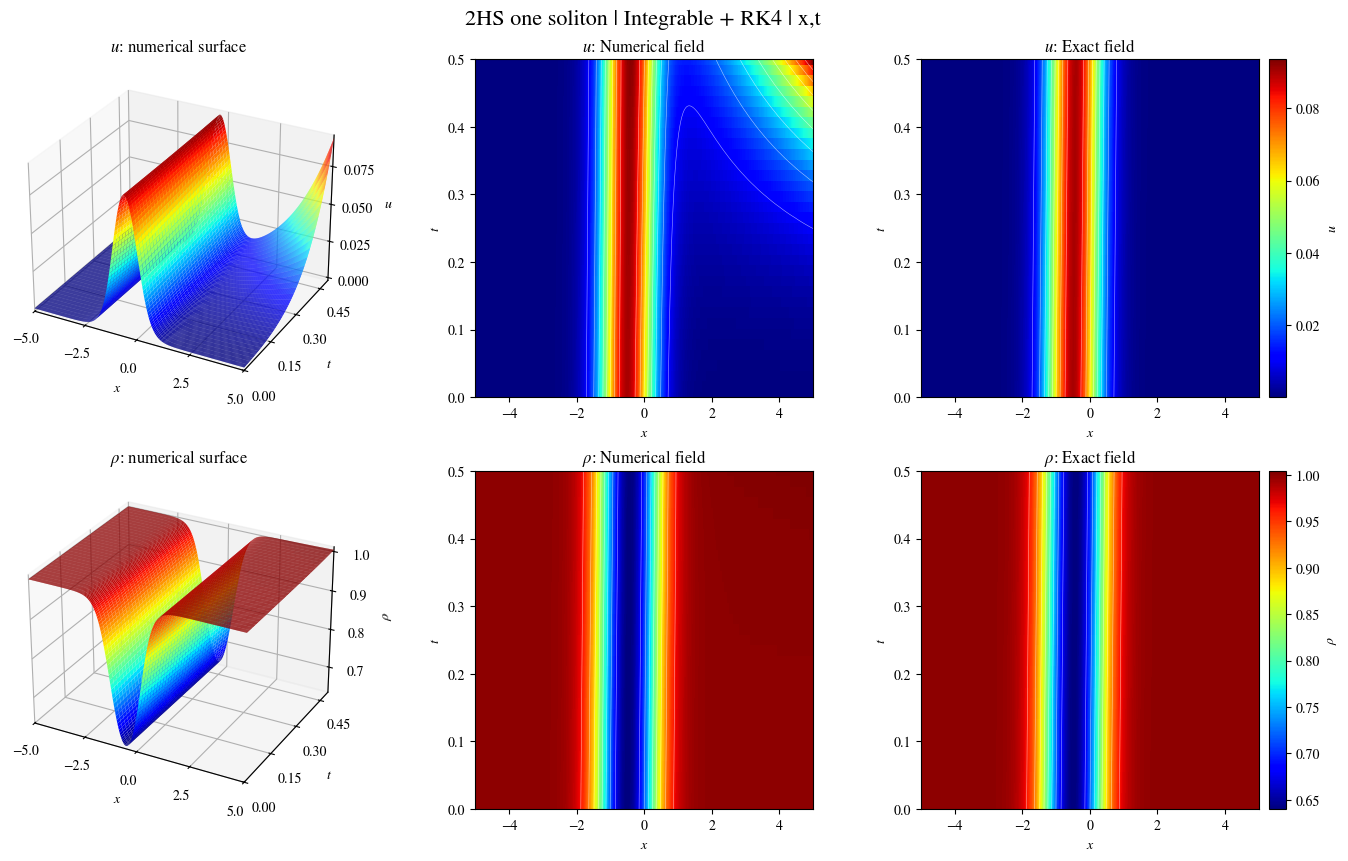

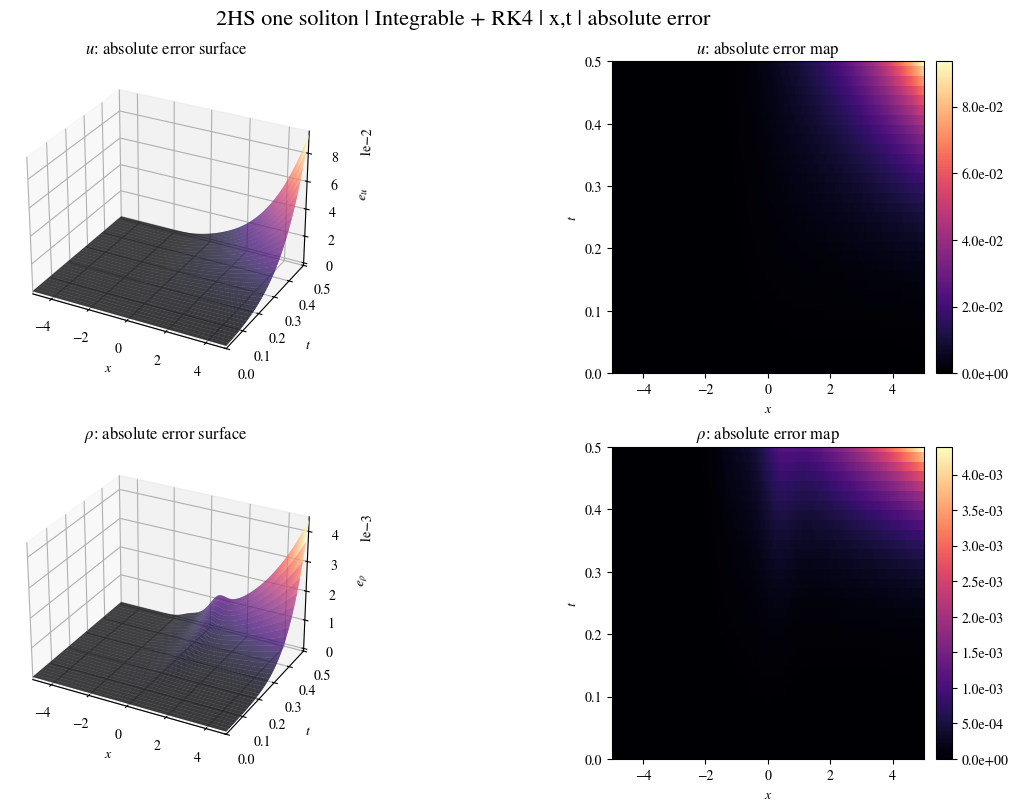

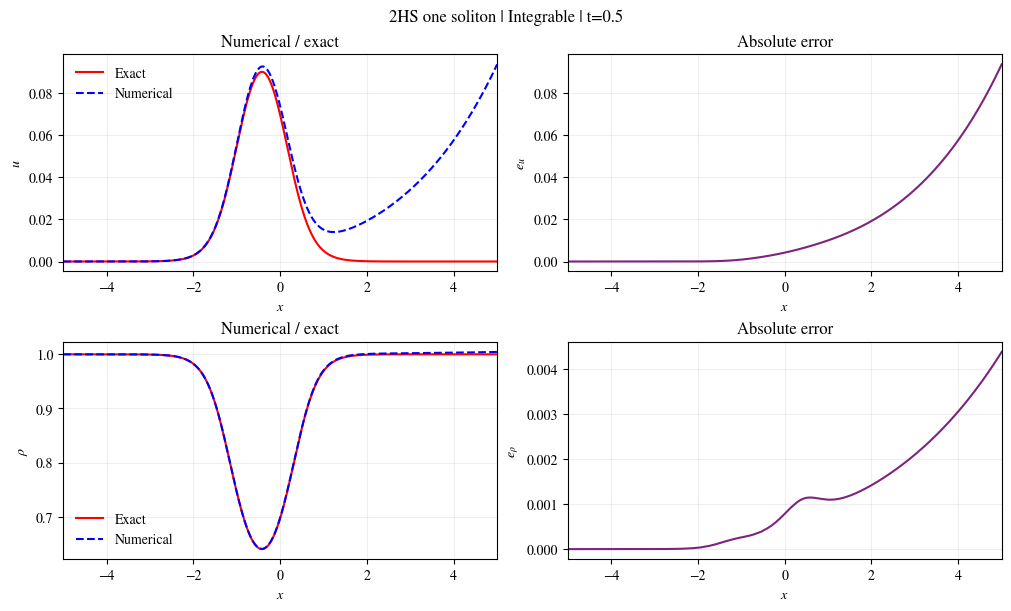

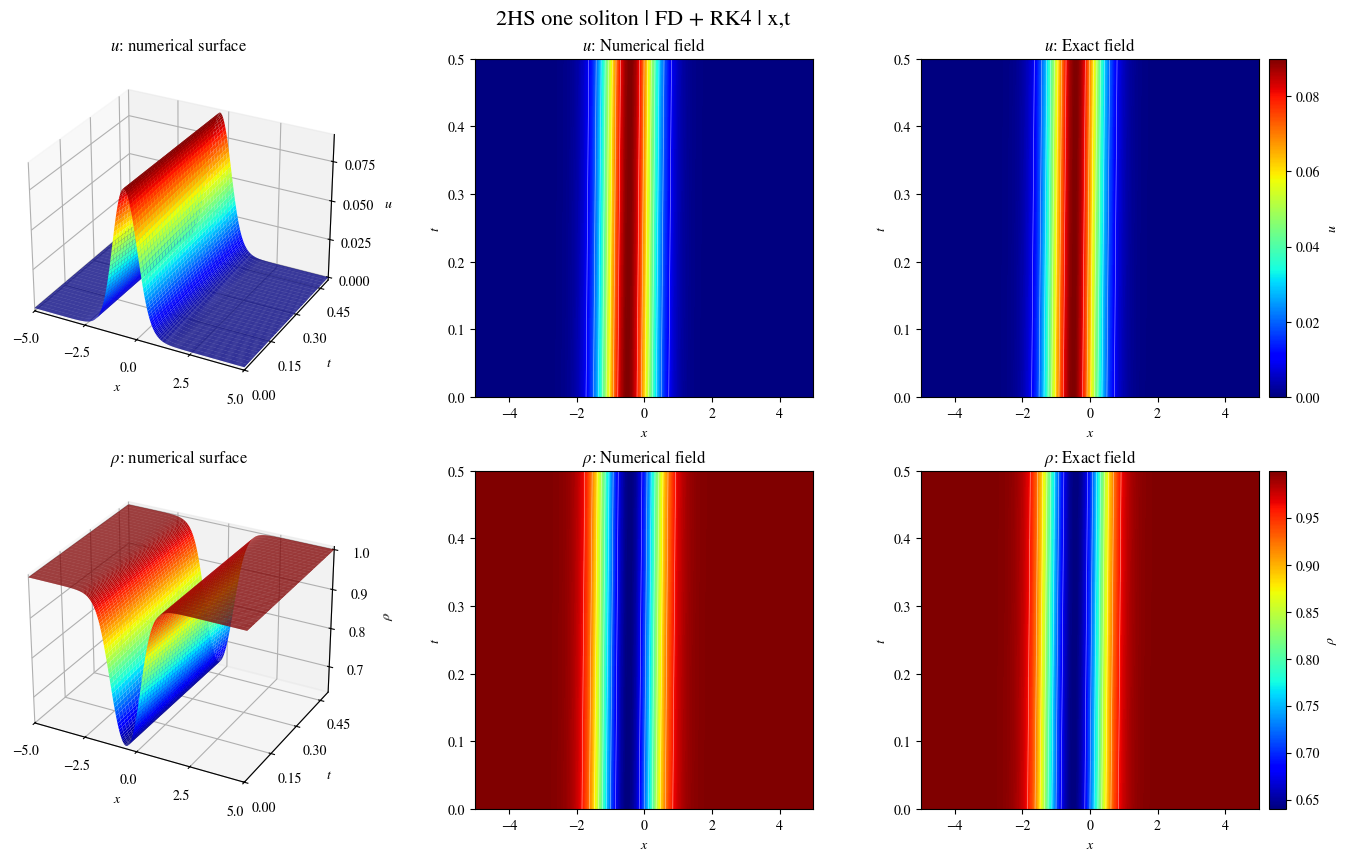

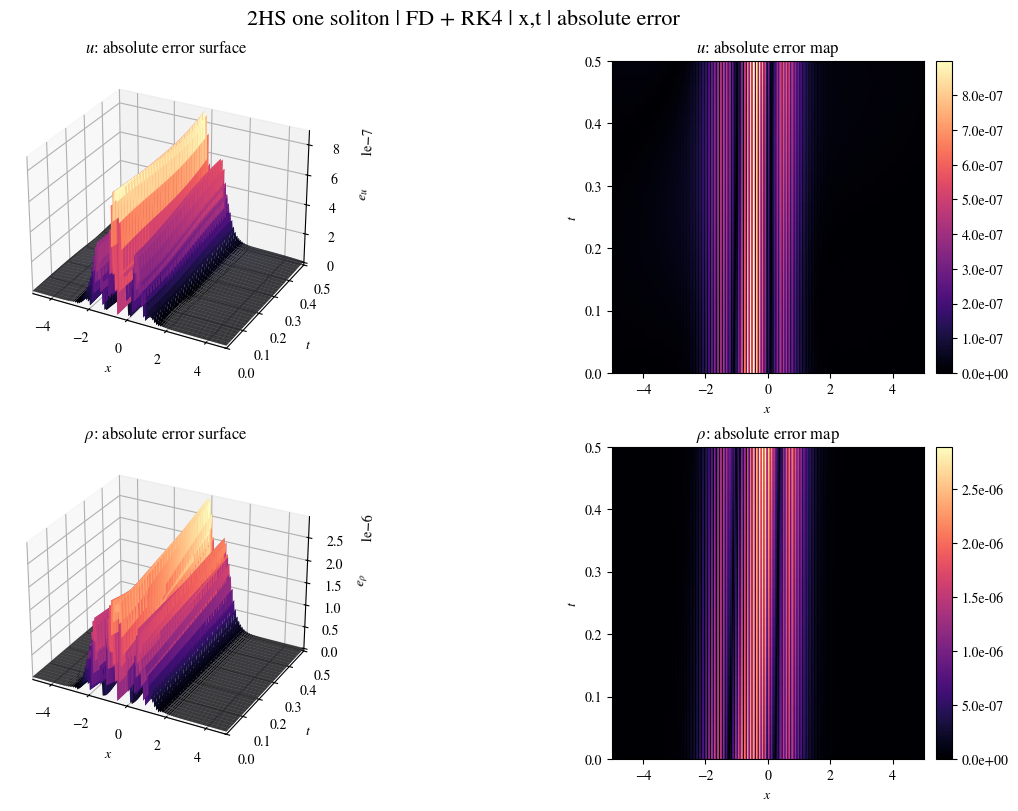

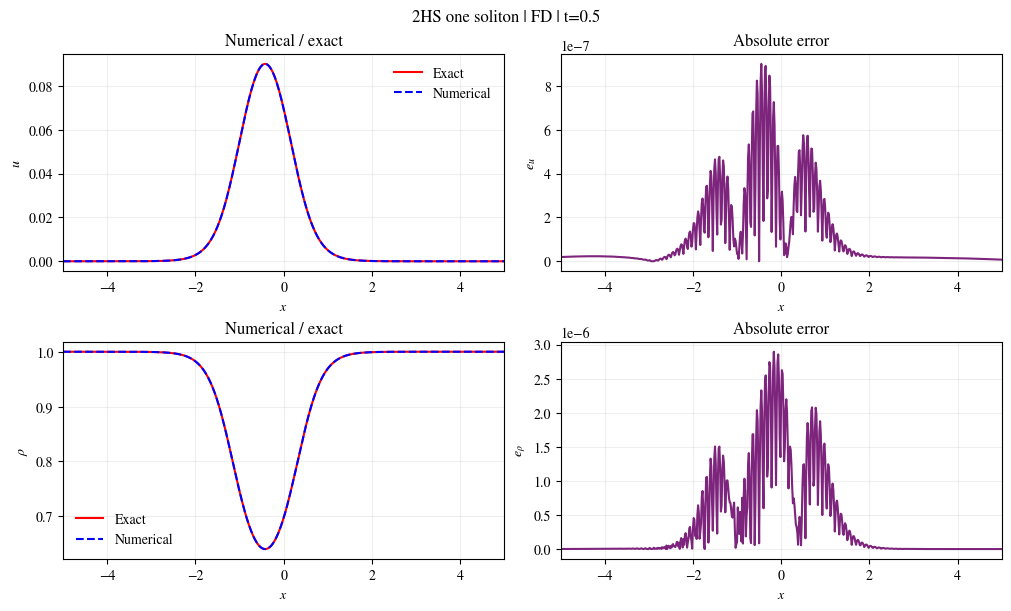

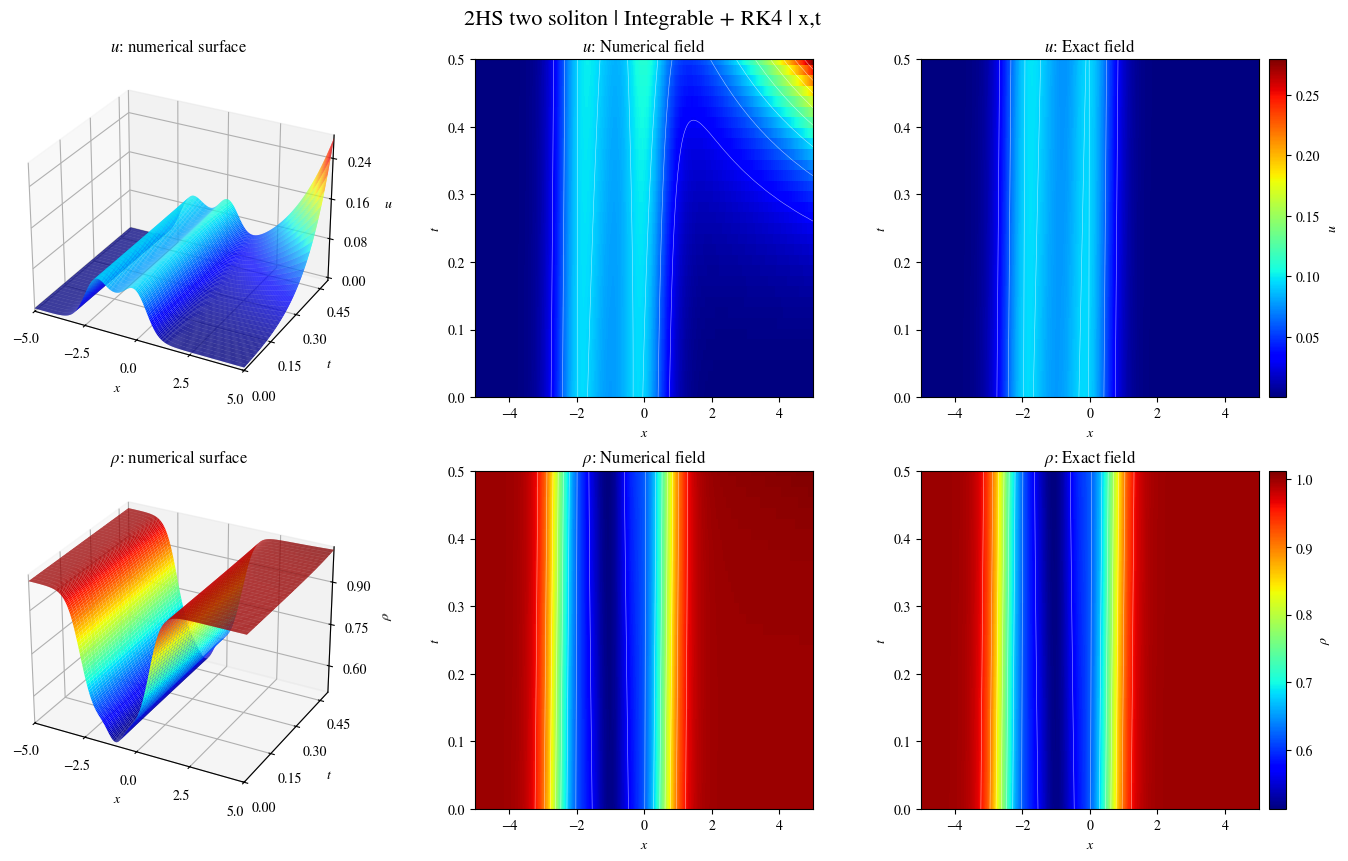

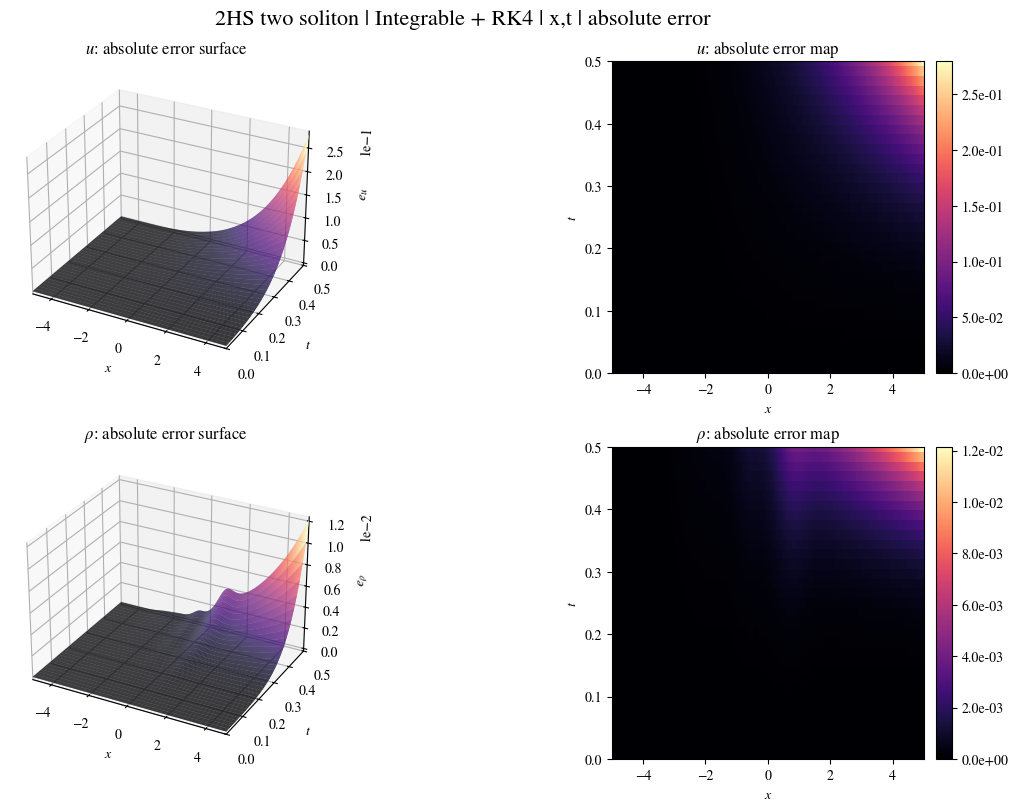

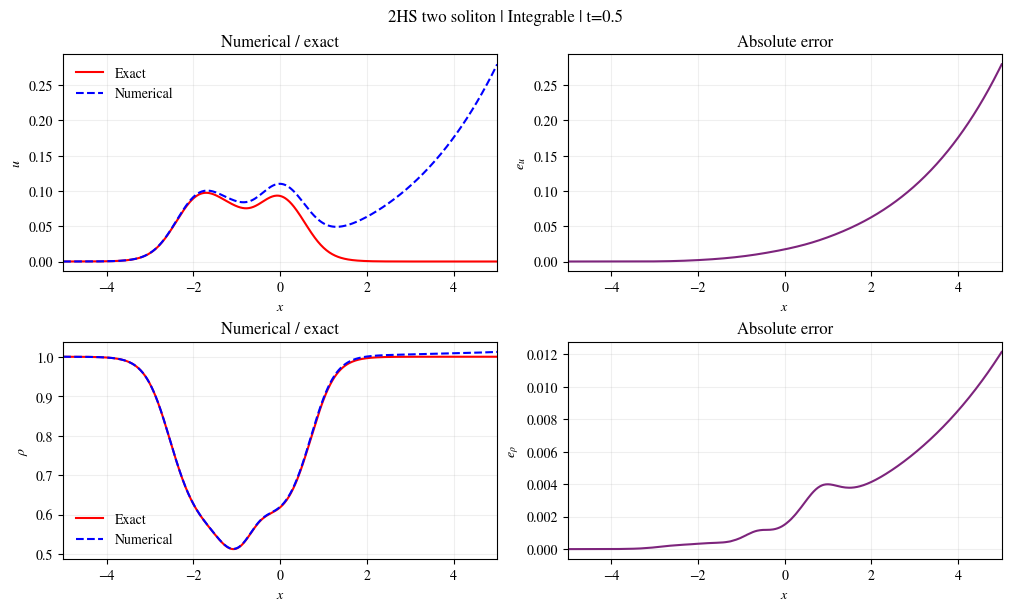

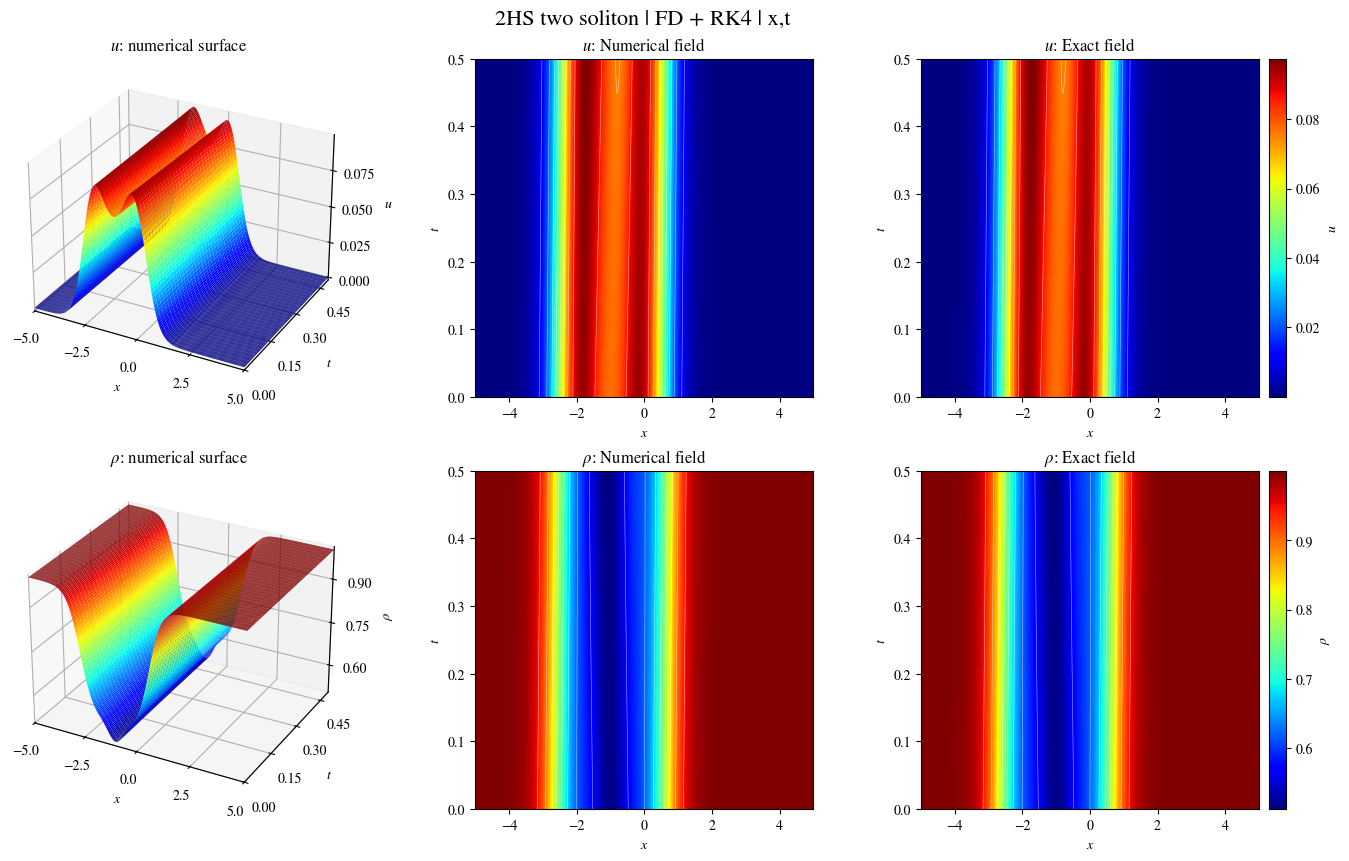

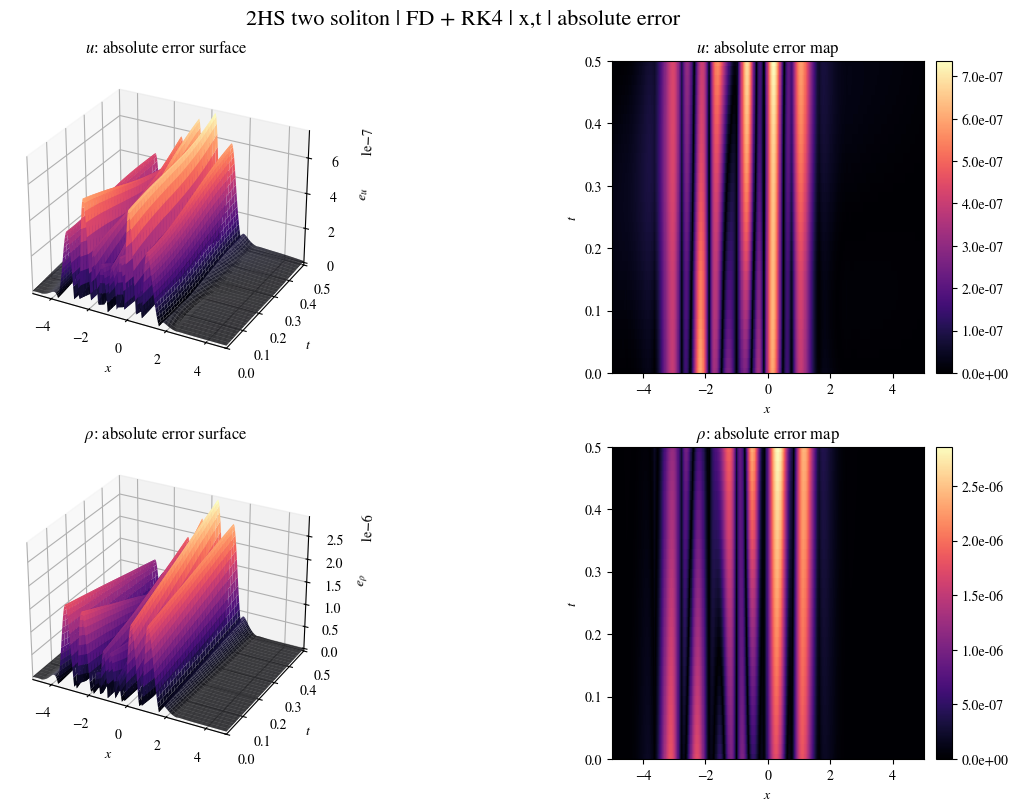

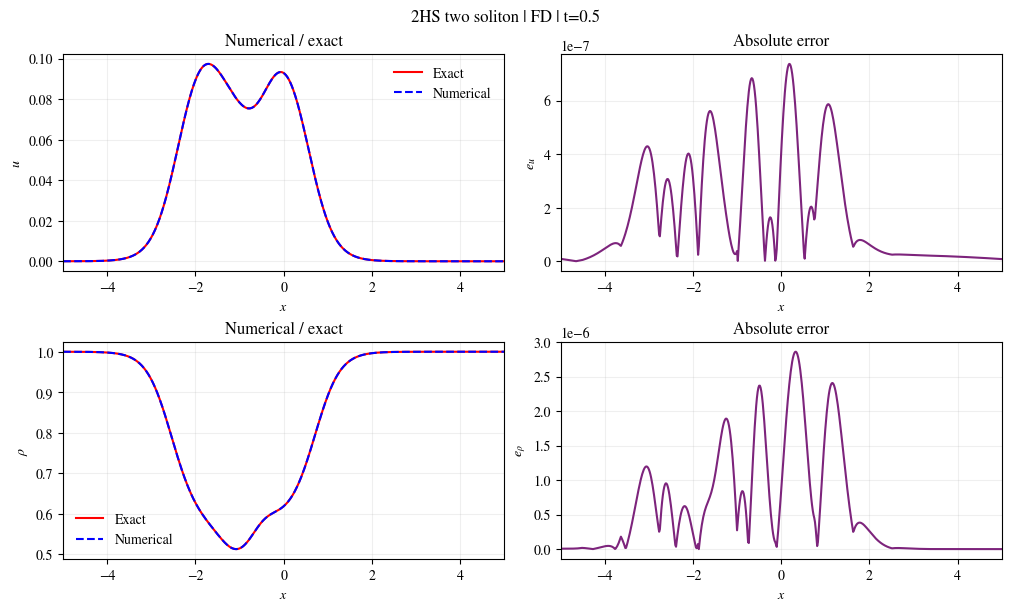

In [19]:
for hs_case in PLOT_CONFIG['cases']:
    history = hs_histories[hs_case]
    checked_window(PLOT_CONFIG['tlim'], (0., history['T']), 'tlim')
    records = history['records']
    for hs_method in PLOT_CONFIG['methods']:
        left = max(float(fields[hs_method][key][0]) for _, fields in records for key in ('x', 'rhoX'))
        right = min(float(fields[hs_method][key][-1]) for _, fields in records for key in ('x', 'rhoX'))
        checked_window(PLOT_CONFIG['xlim'], (left, right), 'xlim')
        x = np.linspace(*PLOT_CONFIG['xlim'], PLOT_CONFIG['xpoints'])
        t = np.array([time for time, _ in records])
        numerical, exact = [], []
        for field, coordinate in (('u', 'x'), ('rho', 'rhoX')):
            numerical.append(np.array([hs_interpolate(fields[hs_method][coordinate], fields[hs_method][field], x)
                                       for _, fields in records]))
            exact.append(np.array([history['reference'](x, time)[field] for time in t]))
        drawing = dict(PLOT_CONFIG, ylim=PLOT_CONFIG['tlim'])
        title = f"2HS {hs_case} soliton | {hs_method} + RK4 | x,t"
        draw_field_panels(x, t, numerical, exact, title, ('u', r'\rho'), drawing, second_axis='t')
        # 固定终点的波形与误差，直接比较数值精度。
        fig, axes = plt.subplots(2, 2, figsize=(10, 6), layout='constrained')
        for row, (field, name) in enumerate((('u', 'u'), ('rho', r'\rho'))):
            axes[row, 0].plot(x, exact[row][-1], 'r-', label='Exact')
            axes[row, 0].plot(x, numerical[row][-1], 'b--', label='Numerical')
            axes[row, 1].plot(x, abs(numerical[row][-1]-exact[row][-1]), color='#7d247c')
            axes[row, 0].set(ylabel=f'${name}$', title='Numerical / exact')
            axes[row, 1].set(ylabel=f'$e_{{{name}}}$', title='Absolute error')
            axes[row, 0].legend(frameon=False)
        for ax in axes.flat:
            ax.set(xlabel='$x$', xlim=PLOT_CONFIG['xlim']);ax.grid(alpha=.2)
        fig.suptitle(f"2HS {hs_case} soliton | {hs_method} | t={t[-1]:g}")
        plt.show()